In [1]:
import pandas as pd
df =pd.read_csv("student_habits_performance.csv")

In [2]:
df.head()

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [6]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   str    
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   str    
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   str    
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   str    
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    str    
 12  internet_quality               1000 non-null   str    
 13  

(1000, 16)

In [7]:
#EDA
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
sns.set(style="whitegrid")

In [10]:
#check missing values
df.isna().sum()

student_id                        0
age                               0
gender                            0
study_hours_per_day               0
social_media_hours                0
netflix_hours                     0
part_time_job                     0
attendance_percentage             0
sleep_hours                       0
diet_quality                      0
exercise_frequency                0
parental_education_level         91
internet_quality                  0
mental_health_rating              0
extracurricular_participation     0
exam_score                        0
dtype: int64

In [12]:
df.dropna(inplace=True)

In [13]:
#duplicates
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 909, dtype: bool

In [14]:
import warnings 
warnings.filterwarnings("ignore")

In [15]:
#statistics
df.describe()

,age,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,exam_score
count,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000,909.000000
mean,20.475248,3.538724,2.504620,1.830363,83.880308,6.474037,3.051705,5.466447,69.558196
std,2.302721,1.469730,1.164802,1.071251,9.453622,1.218943,2.035632,2.857525,16.929436
min,17.000000,0.000000,0.000000,0.000000,56.000000,3.200000,0.000000,1.000000,18.400000
25%,18.000000,2.500000,1.700000,1.000000,77.500000,5.600000,1.000000,3.000000,58.400000
50%,20.000000,3.500000,2.500000,1.800000,84.200000,6.500000,3.000000,5.000000,70.400000
75%,22.000000,4.500000,3.300000,2.600000,90.700000,7.300000,5.000000,8.000000,81.300000
max,24.000000,8.300000,7.200000,5.400000,100.000000,10.000000,6.000000,10.000000,100.000000


In [19]:
df.describe(include="object").columns

Index(['student_id', 'gender', 'part_time_job', 'diet_quality',
       'parental_education_level', 'internet_quality',
       'extracurricular_participation'],
      dtype='str')

In [21]:
# Define categorical columns
categorical_cols = [
    'gender',
    'part_time_job',
    'diet_quality',
    'parental_education_level',
    'internet_quality',
    'extracurricular_participation'
]

print(categorical_cols)

['gender', 'part_time_job', 'diet_quality', 'parental_education_level', 'internet_quality', 'extracurricular_participation']


In [24]:
for col in categorical_cols:
    print(f"Value counts for{col}:\n{df[col].value_counts()}")

Value counts forgender:
gender
Male      440
Female    433
Other      36
Name: count, dtype: int64
Value counts forpart_time_job:
part_time_job
No     713
Yes    196
Name: count, dtype: int64
Value counts fordiet_quality:
diet_quality
Fair    396
Good    347
Poor    166
Name: count, dtype: int64
Value counts forparental_education_level:
parental_education_level
High School    392
Bachelor       350
Master         167
Name: count, dtype: int64
Value counts forinternet_quality:
internet_quality
Good       410
Average    352
Poor       147
Name: count, dtype: int64
Value counts forextracurricular_participation:
extracurricular_participation
No     620
Yes    289
Name: count, dtype: int64


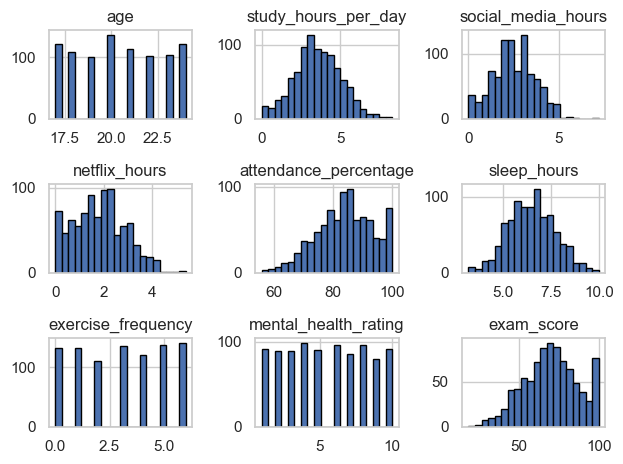

In [25]:
#histograms for numerical values
df.hist(bins=20, edgecolor="black")
plt.tight_layout()
plt.show()

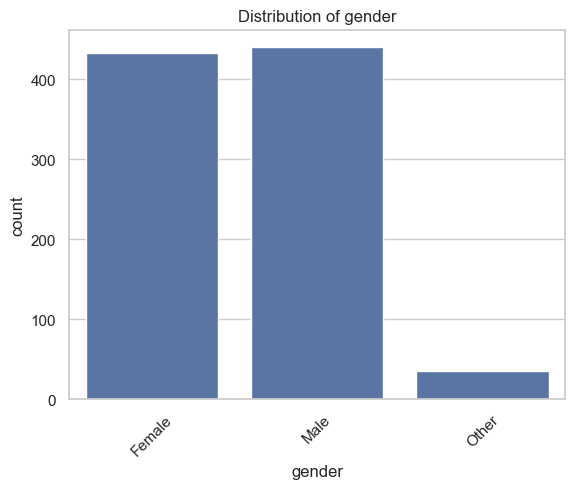

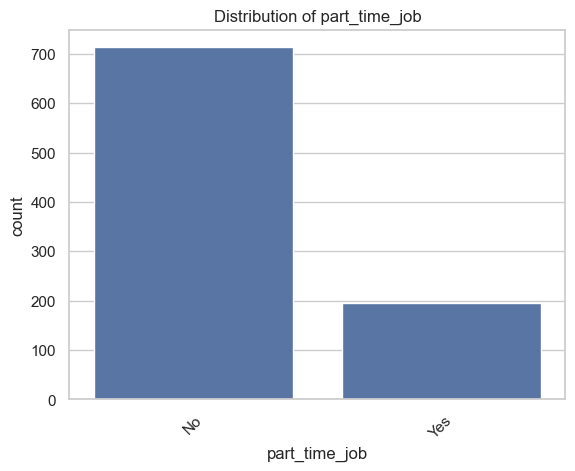

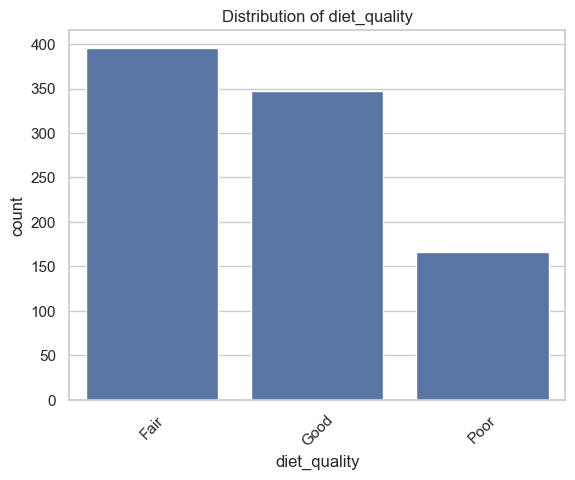

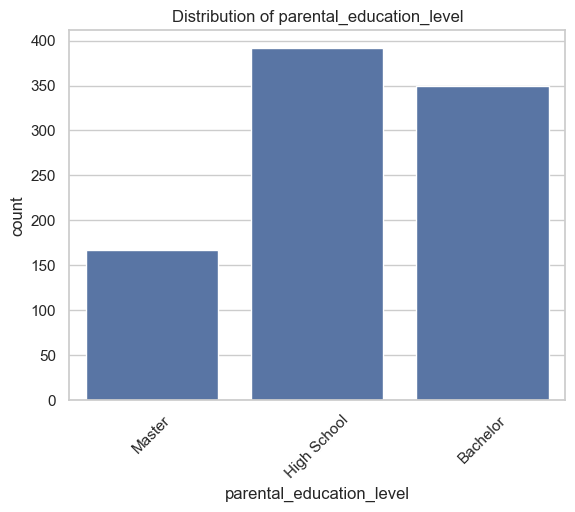

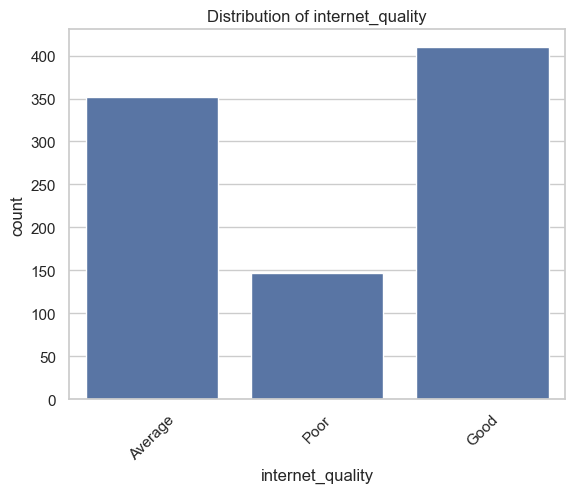

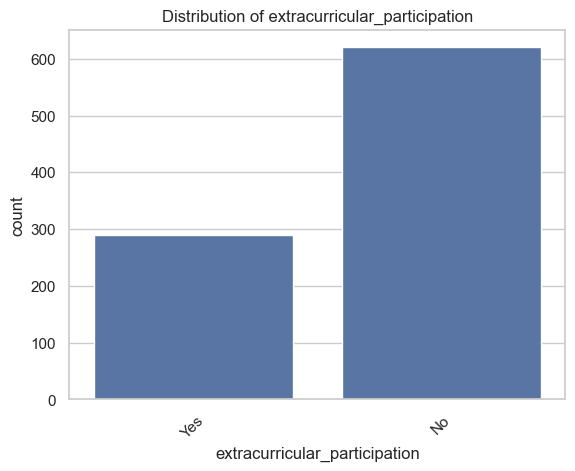

In [26]:
#count plots 
for col in categorical_cols:
  sns.countplot(data=df,x=col)
  plt.title(f"Distribution of {col}")
  plt.xticks(rotation=45)
  plt.show()

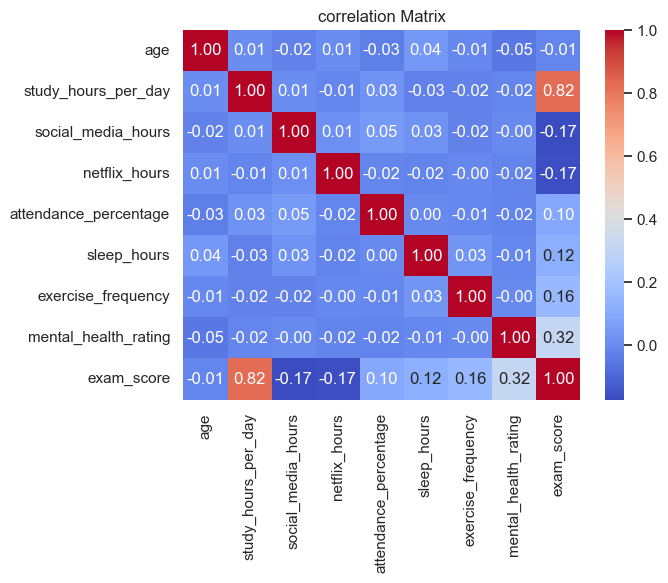

In [27]:
#correlation_matrix
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("correlation Matrix")
plt.show()

In [28]:
df.describe().columns

Index(['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
       'attendance_percentage', 'sleep_hours', 'exercise_frequency',
       'mental_health_rating', 'exam_score'],
      dtype='str')

In [34]:
# Numerical features
num_features = [
    'age',
    'study_hours_per_day',
    'social_media_hours',
    'netflix_hours',
    'attendance_percentage',
    'sleep_hours',
    'exercise_frequency',
    'mental_health_rating'
]

In [33]:
df.select_dtypes(include=['int64','float64']).columns

Index(['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours',
       'attendance_percentage', 'sleep_hours', 'exercise_frequency',
       'mental_health_rating', 'exam_score'],
      dtype='str')

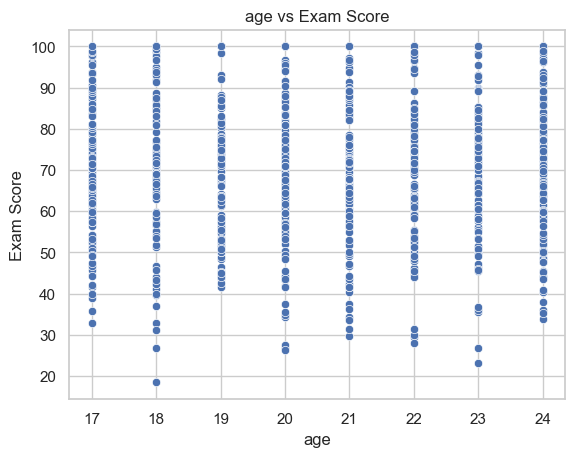

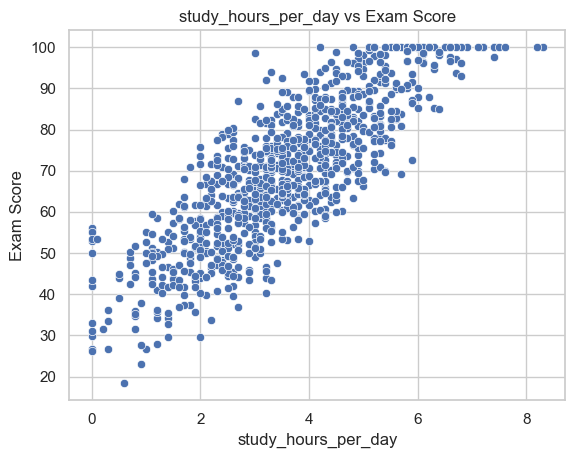

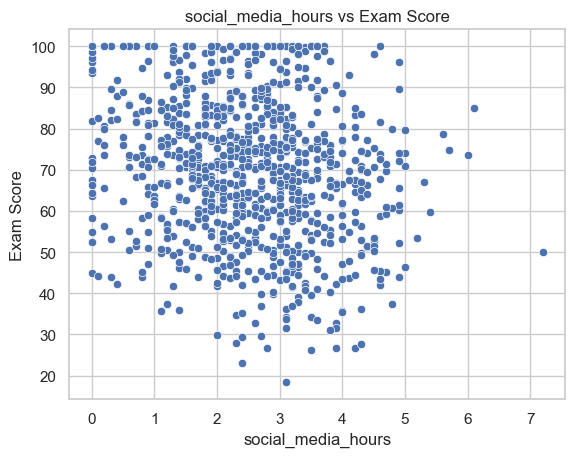

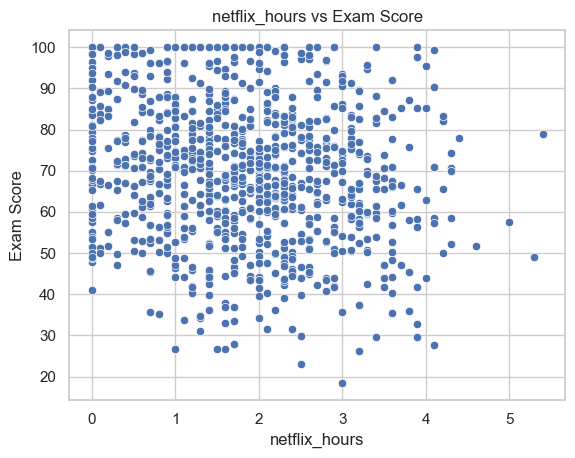

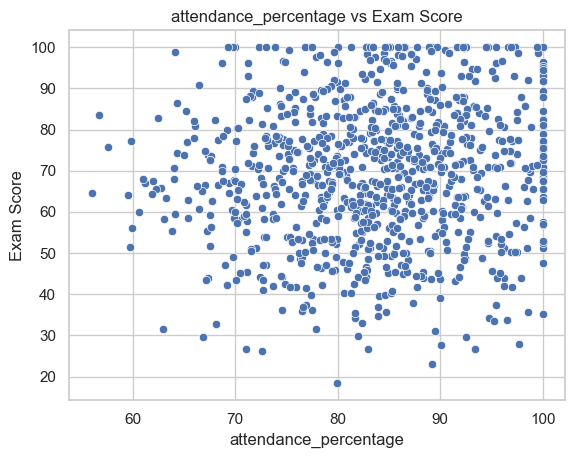

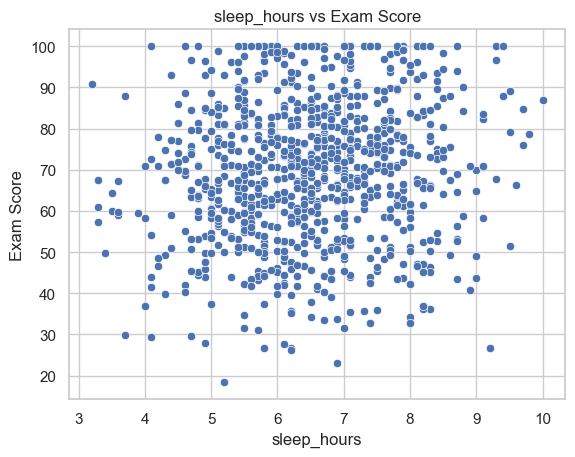

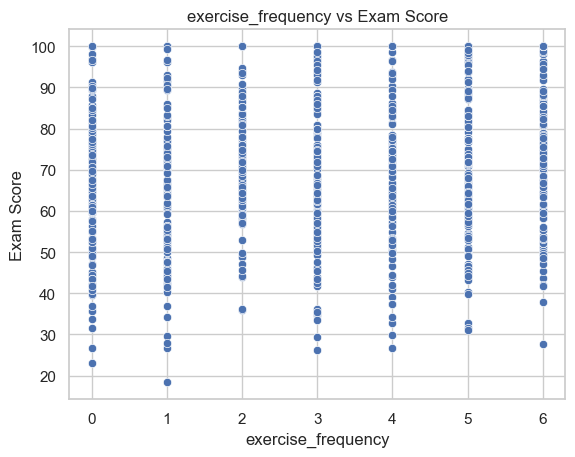

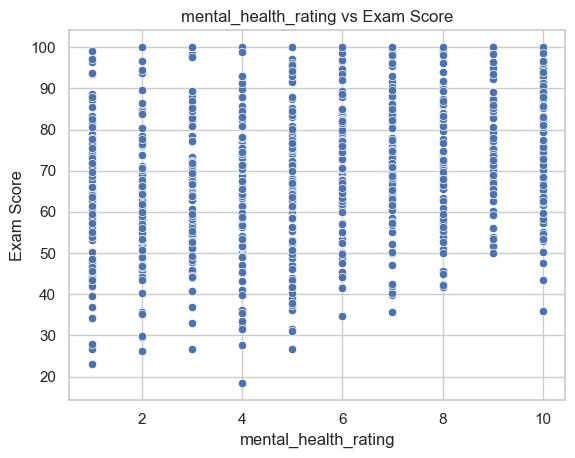

In [35]:
for feature in num_features:
    sns.scatterplot(
        data=df,
        x=feature,
        y="exam_score"
    )
    
    plt.title(f"{feature} vs Exam Score")
    plt.xlabel(feature)
    plt.ylabel("Exam Score")
    plt.show()

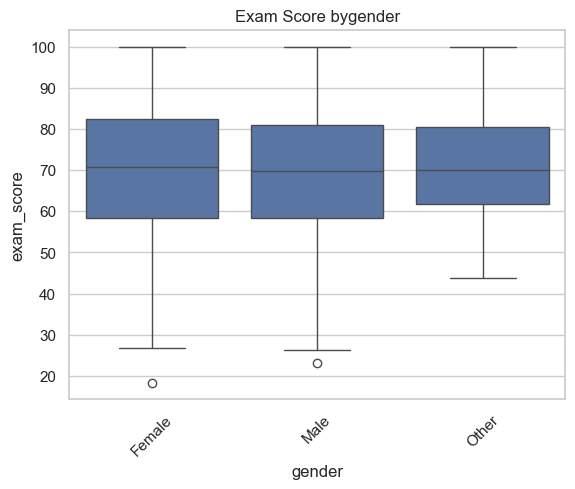

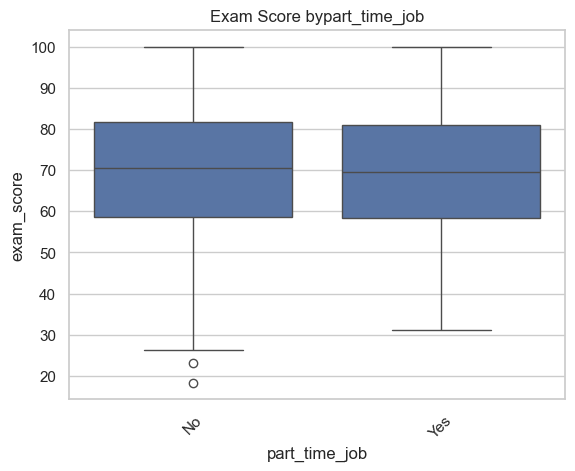

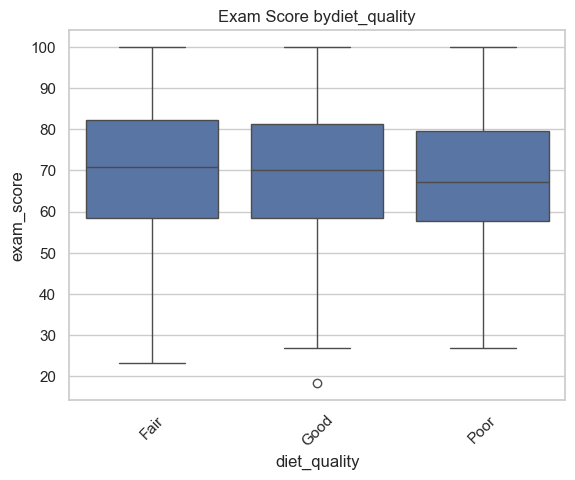

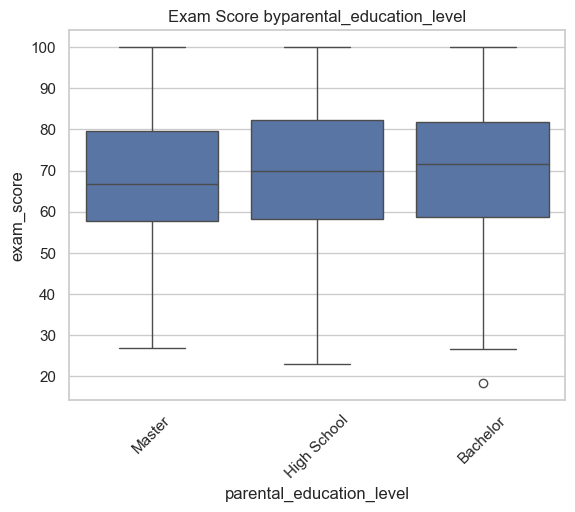

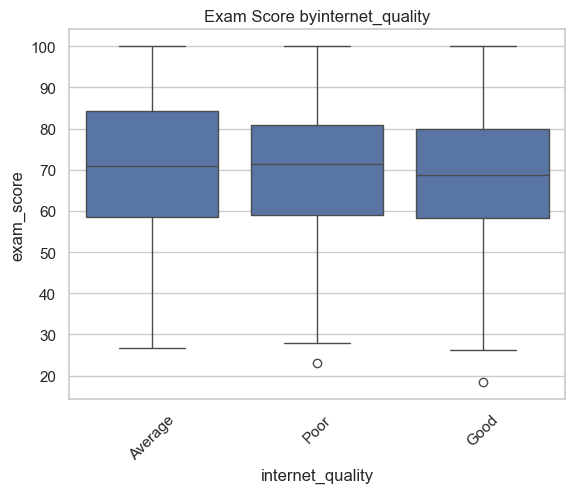

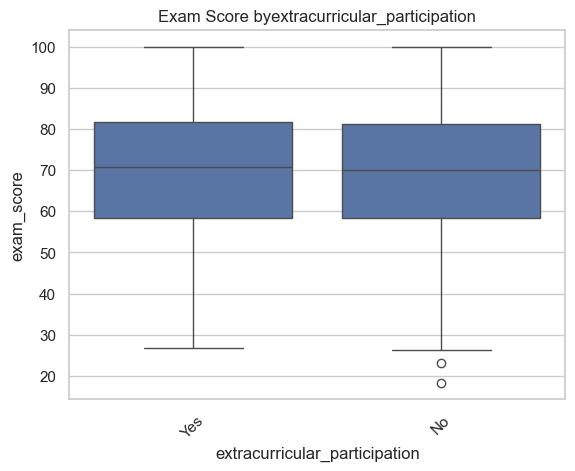

In [36]:
for col in categorical_cols:
  sns.boxplot(data=df, x=col, y="exam_score")
  plt.title(f"Exam Score by{col}")
  plt.xticks(rotation =45)
  plt.show()

In [37]:
#feature engineering
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor



In [38]:
df.columns

Index(['student_id', 'age', 'gender', 'study_hours_per_day',
       'social_media_hours', 'netflix_hours', 'part_time_job',
       'attendance_percentage', 'sleep_hours', 'diet_quality',
       'exercise_frequency', 'parental_education_level', 'internet_quality',
       'mental_health_rating', 'extracurricular_participation', 'exam_score'],
      dtype='str')

In [39]:
df.head(2)

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0


In [40]:
features=["study_hours_per_day","attendance_percentage","mental_health_rating", "sleep_hours","part_time_job"]

In [41]:
target="exam_score"


In [42]:
df_model =df[features +[target]].copy()

In [43]:
df_model

,study_hours_per_day,attendance_percentage,mental_health_rating,sleep_hours,part_time_job,exam_score
0,0.0,85.0,8,8.0,No,56.2
1,6.9,97.3,8,4.6,No,100.0
2,1.4,94.8,1,8.0,No,34.3
3,1.0,71.0,1,9.2,No,26.8
4,5.0,90.9,1,4.9,No,66.4
...,...,...,...,...,...,...
995,2.6,77.0,6,7.5,No,76.1
996,2.9,86.0,6,6.8,Yes,65.9
997,3.0,61.9,9,6.5,No,64.4
998,5.4,100.0,1,7.6,Yes,69.7


In [44]:
le =LabelEncoder()


In [47]:
df_model["part_time_job"] = le.fit_transform(df_model["part_time_job"])

In [48]:
X = df_model[features]

In [50]:
y = df_model[target]

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2)

In [52]:
len(y_train)

727

In [54]:
models = {
    "LinearRegression": {
        "model": LinearRegression(),
        "params": {}
    },

    "DecisionTree": {
        "model": DecisionTreeRegressor(),
        "params": {
            "max_depth": [3, 5, 10],
            "min_samples_split": [2]
        }
    },

    "RandomForest": {
        "model": RandomForestRegressor(),
        "params": {
            "n_estimators": [50, 100],
            "max_depth": [5, 10]
        }
    }
}

In [55]:
best_models =[]

In [57]:
best_models = []

for name, config in models.items():

    print(f"Training {name}")

    grid = GridSearchCV(
        config["model"],
        config["params"],
        cv=5,
        scoring="neg_mean_squared_error"
    )

    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    r2 = r2_score(y_test, y_pred)

    best_models.append({
        "model": name,
        "best_params": grid.best_params_,
        "rmse": rmse,
        "r2": r2
    })

print("Training completed!")

Training LinearRegression
Training DecisionTree
Training RandomForest
Training completed!


In [60]:
results_df = pd.DataFrame(best_models)

results_df

,model,best_params,rmse,r2
0,LinearRegression,{},7.245281,0.791529
1,DecisionTree,"{'max_depth': 5, 'min_samples_split': 2}",8.626087,0.704496
2,RandomForest,"{'max_depth': 10, 'n_estimators': 100}",7.803395,0.758174


In [61]:
results_df = results_df.sort_values(by="rmse", ascending=True)

results_df

,model,best_params,rmse,r2
0,LinearRegression,{},7.245281,0.791529
2,RandomForest,"{'max_depth': 10, 'n_estimators': 100}",7.803395,0.758174
1,DecisionTree,"{'max_depth': 5, 'min_samples_split': 2}",8.626087,0.704496


In [63]:
import joblib

best_row = results_df.sort_values(by="rmse").iloc[0]

best_row

model          LinearRegression
best_params                  {}
rmse                   7.245281
r2                     0.791529
Name: 0, dtype: object

In [64]:
best_mmodel_name = best_row["model"]

In [65]:
best_row

model          LinearRegression
best_params                  {}
rmse                   7.245281
r2                     0.791529
Name: 0, dtype: object

In [66]:
best_mmodel_name = best_row["model"]

In [68]:
best_model_name = best_row["model"]

best_model_name

'LinearRegression'

In [69]:
best_model_config = models[best_model_name]


In [70]:
best_model_config

{'model': LinearRegression(), 'params': {}}

In [71]:
final_model = best_model_config["model"]

In [72]:
final_model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
final_model.predict(X_test)

In [74]:
joblib.dump(final_model, "best_model.pkl")

['best_model.pkl']

In [75]:
joblib.load("best_model.pkl").predict(X_test)

array([ 61.81291391,  82.66920556,  61.47538447,  74.30904731,
        94.56521015,  80.61992577,  44.07954472,  62.15277743,
        81.1148883 ,  48.92767151,  78.70663792,  62.33964812,
        42.51199279,  89.92801771,  71.56094773, 101.01138266,
        63.46863323,  58.60039915,  67.37855373,  76.501325  ,
        85.31042026,  73.32456053,  70.95686872,  57.59364973,
        74.41638106, 100.00884675,  78.93711347,  70.56670815,
        73.66672527,  87.76819727,  57.75569122, 103.39848608,
        72.6281173 ,  66.42058582,  50.57237348,  54.2248526 ,
        82.34672584,  93.907731  ,  50.09576014, 104.70803339,
        81.52560059,  76.46225033,  66.09964476,  67.76353877,
        60.9230965 ,  63.60625277,  53.49737655,  67.50594954,
        73.1673932 ,  53.22219131,  66.7077738 , 109.86076479,
        87.69201972,  68.10932257,  58.73592725,  56.58691108,
        76.84828965,  70.10700083,  45.83696497,  78.89418139,
        54.12381522,  80.45227491,  57.99851846,  38.17